# CCF guide

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import colorcet as cc
import cmocean as cmo

from popurri import spectrum
from popurri import telluricutils
from popurri import plotutils

from raccoon import crosscorr

# mpl.rcdefaults()
plotutils.mpl_custom_basic()
plotutils.mpl_size_same(font_size=18)

# # Testing
# %load_ext autoreload
# %autoreload 2

## Observations

### Read

In [2]:
lisfil = [
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20160318T22h26m50s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20160327T21h25m39s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20160411T20h12m48s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20170109T02h38m37s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20170302T20h25m06s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20170412T20h02m25s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20171230T01h42m48s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20180102T01h14m44s-sci-gtoc-vis_A.fits',
]
inst = 'carmvis'
dirout = './ccf_guide/'

# Read spectrum from filin
lisspec = spectrum.Spectra(lisfil, inst, dirout=dirout)

# vars(lisspec)

### Plot spectra

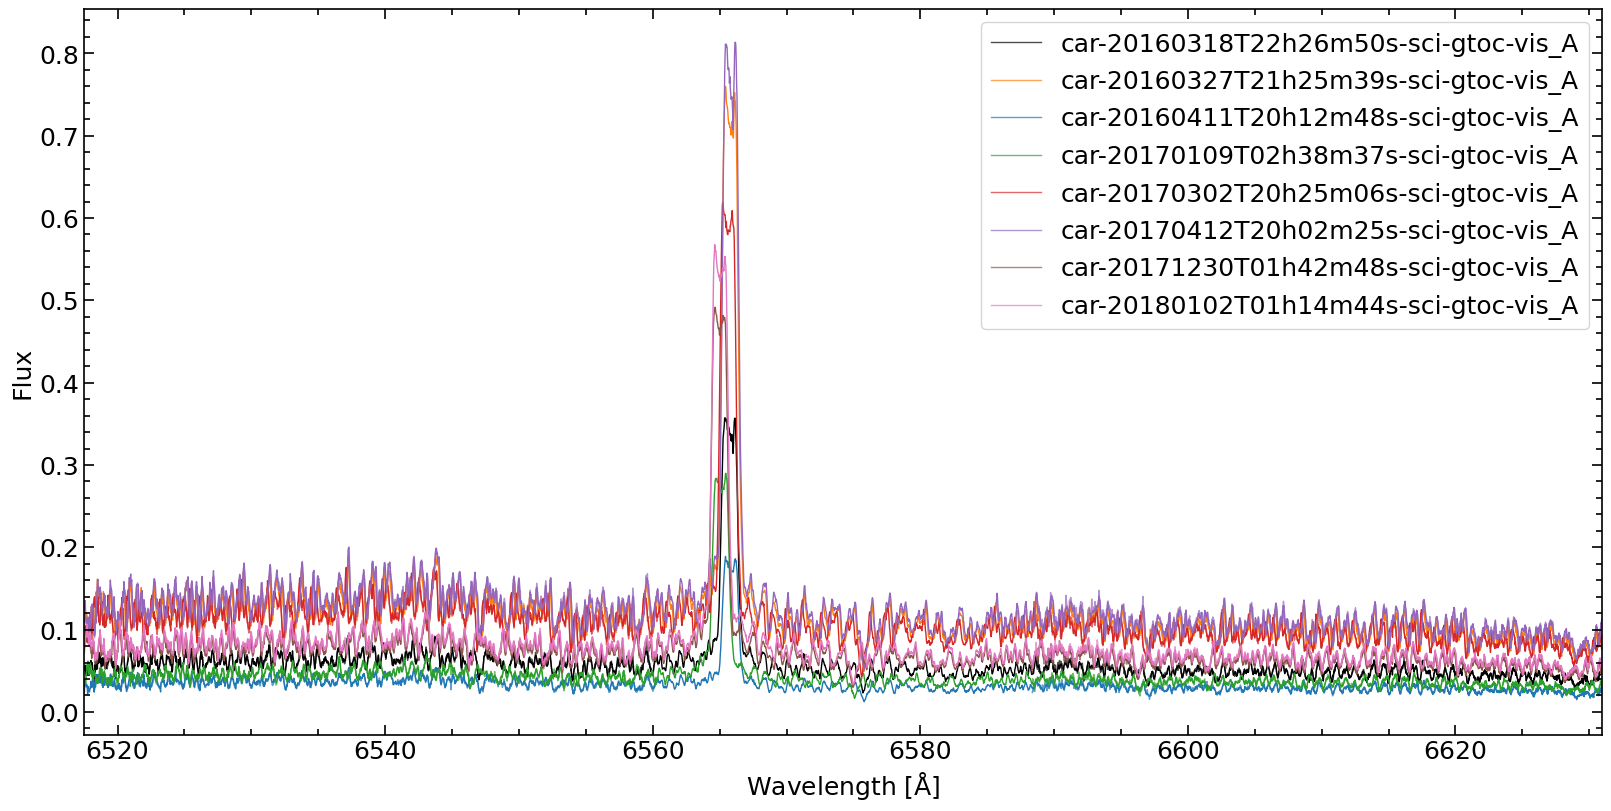

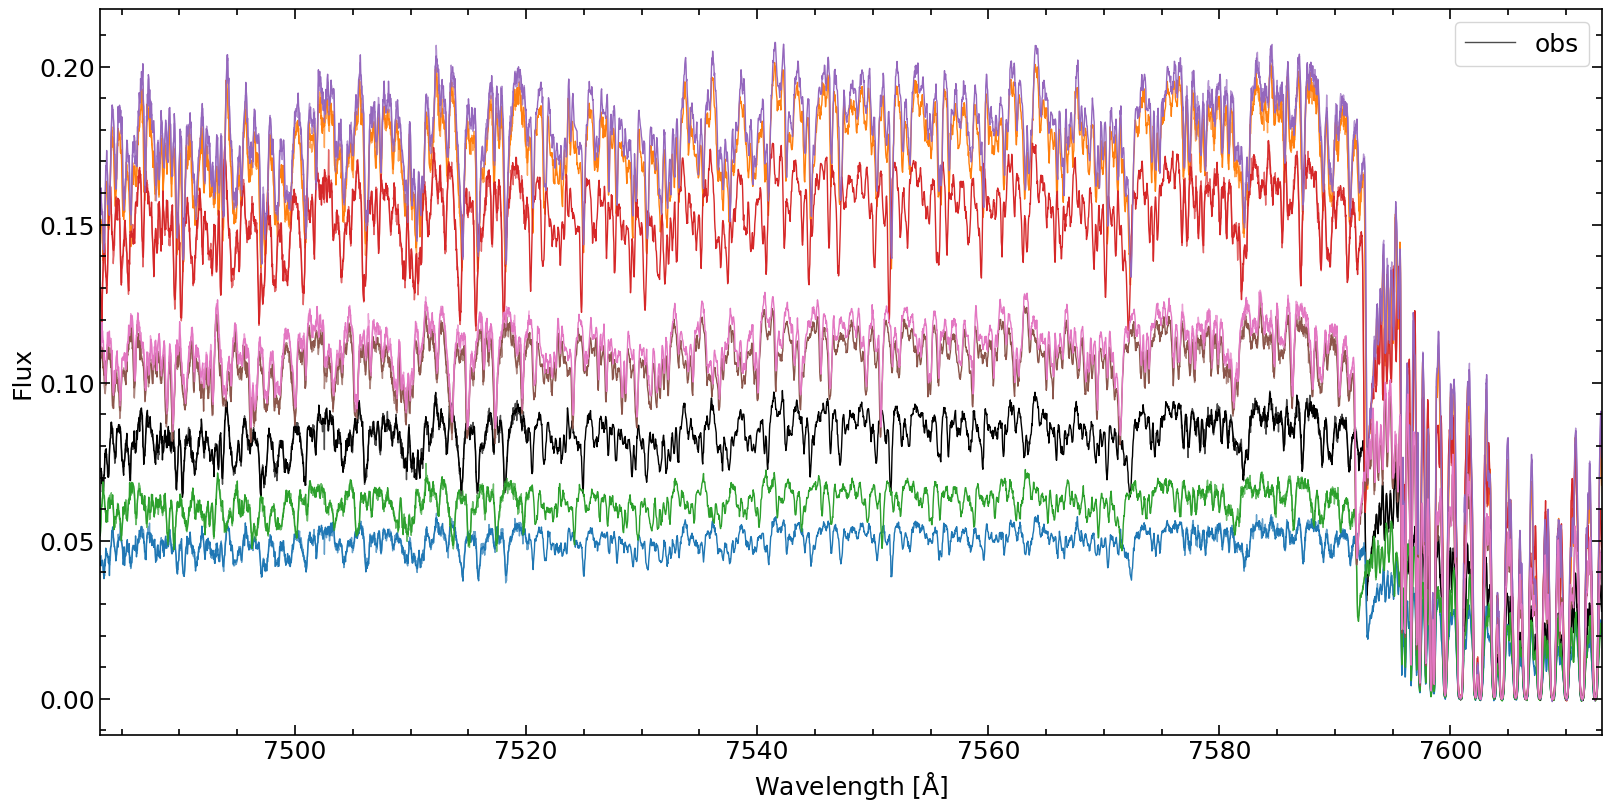

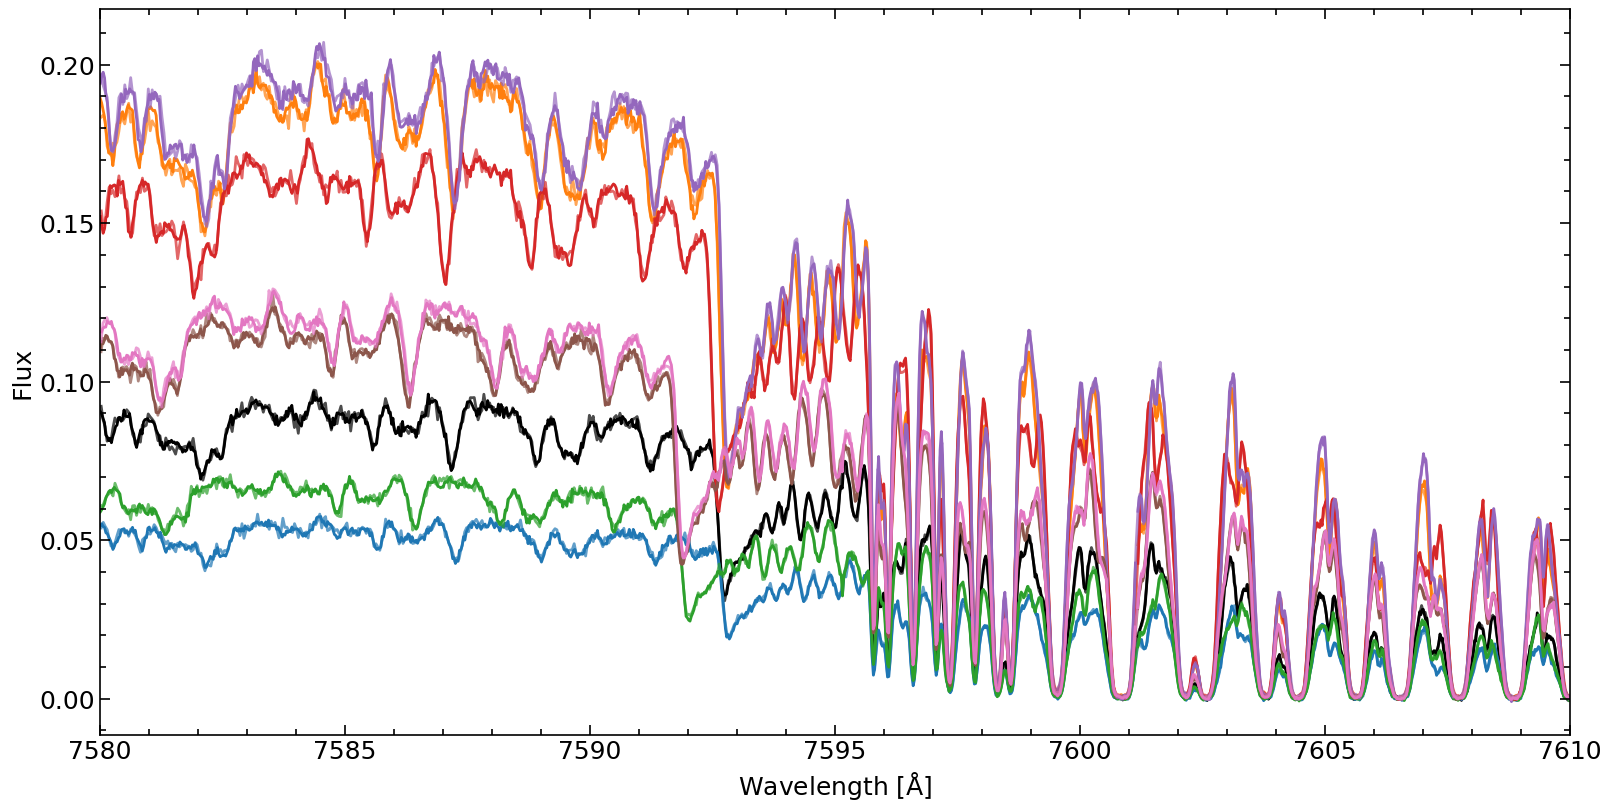

In [3]:
# Plot observations

# Plot Halpha order
lisspec.fig_spectra(sh=True, sv=False, ords=np.arange(25, 26), figsize=(16, 8), legendwhich='all', legendlabel='obs')

# Plot order with tellurics
lisspec.fig_spectra(sh=True, sv=False, ords=np.arange(37, 38), figsize=(16, 8), legendwhich='first', legendlabel='obs')
# Zoom in
lisspec.fig_spectra(sh=True, sv=False, wmin=7580, wmax=7610, figsize=(16, 8), lw=2)

### Plot some properties

In [4]:
# TODO

## Binary mask

### Read

In [5]:
filmask = '/Users/marina/work/code/raccoon/raccoon/data/mask/CARM_VIS/J07274+052serval_tellbervmax_fwhm2.00-30.00_contrminmin0.06_depthwq0.60_contrastmeanfwhm-1.mas'
mask = crosscorr.Model(filmask, modeltype='mask', tag='defaut_J07274+052serval',  dirout=dirout)

### Plot

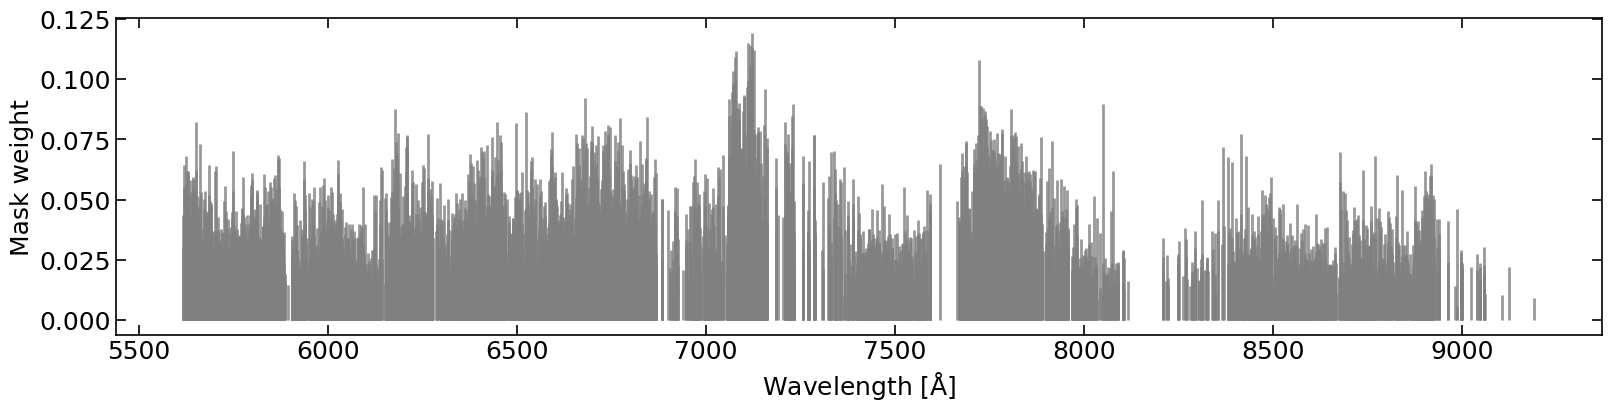

In [6]:
# Plot mask
mask.fig_mask(sh=True, sv=False)

## Telluric mask

### Read

In [7]:
filtell = '/Users/marina/work/code/raccoon/raccoon/data/tellurics/CARM_VIS/telluric_mask_carm_short.dat'
tellmask = telluricutils.Mask(filin=filtell, dirout=dirout, diroutplot=dirout)

### Plot

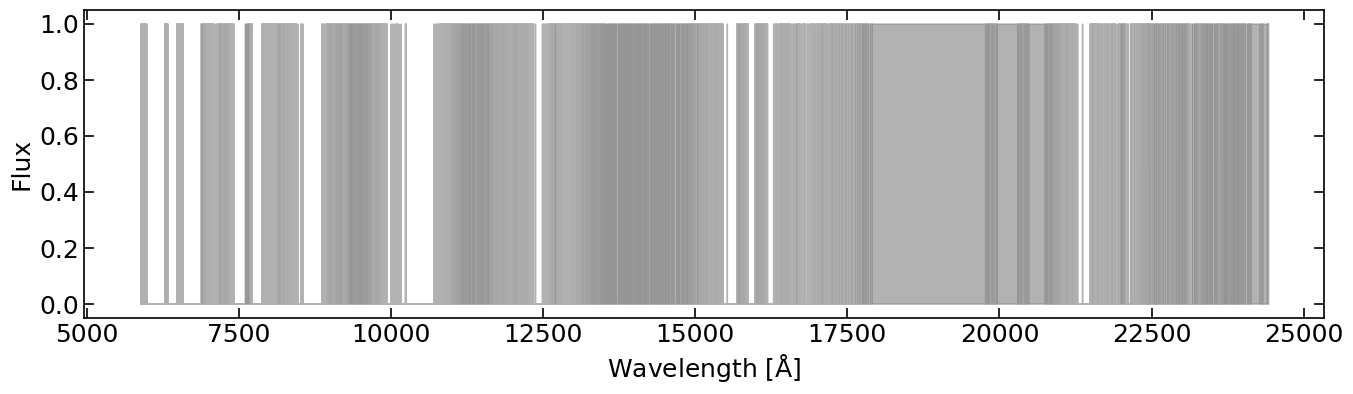

In [8]:
# Plot telluric mask
tellmask.fig_mask(sh=True, sv=False)

## Plot all inputs

Plot spectra, binary mask, and telluric mask.

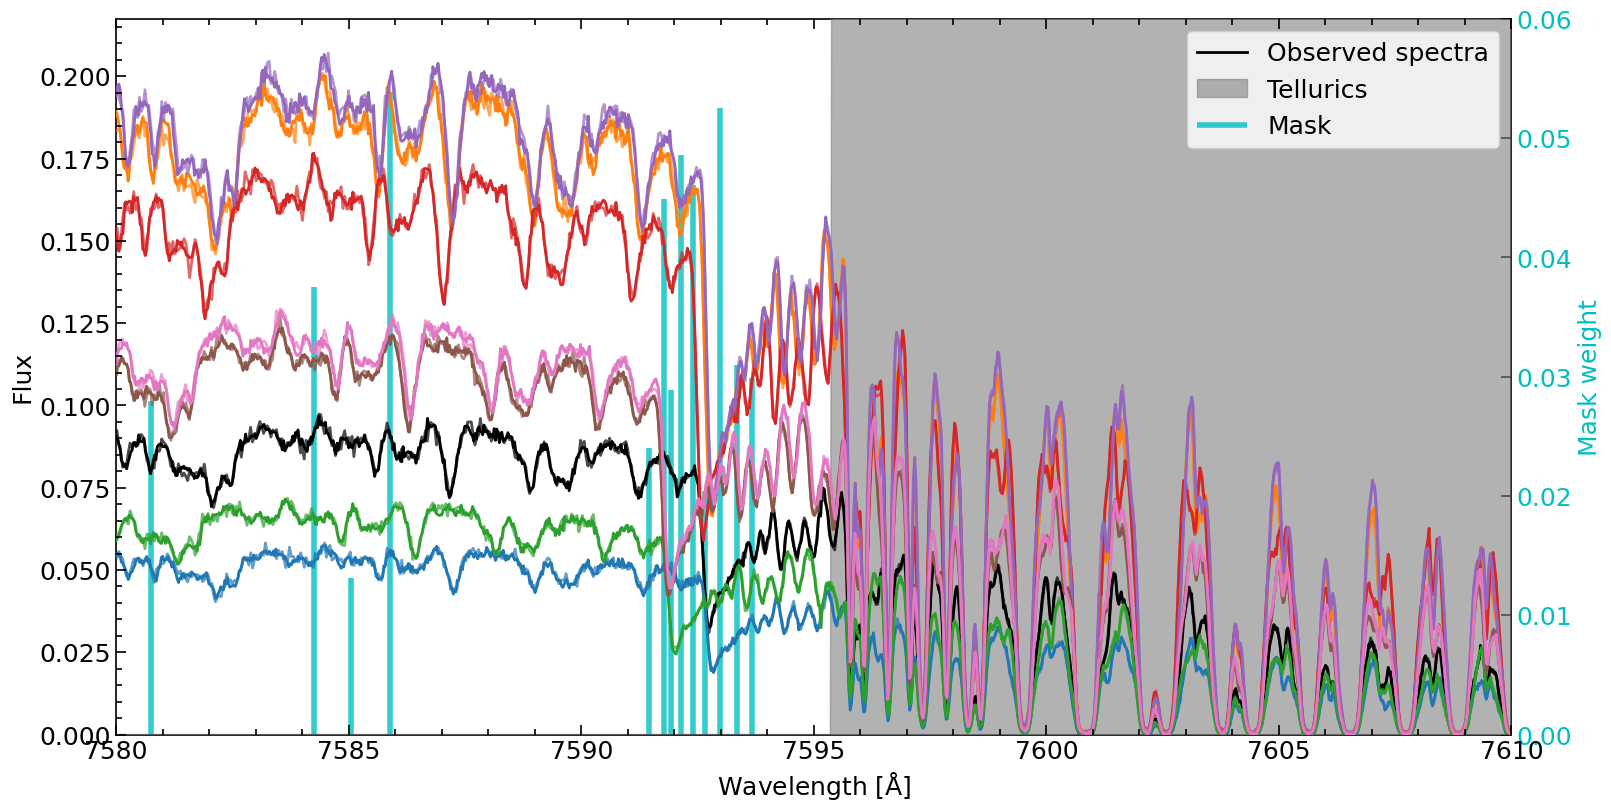

(None, None)

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(16, 8), constrained_layout=True)
# Spectrum
ax = lisspec.plot_spectra(ax=ax, wmin=7580, wmax=7610, lw=2, legendwhich='first', legendlabel='Observed spectra')
ylim = ax.get_ylim()

# # Binary mask
# ax = mask.plot_mask(ax=ax, ymin=ylim[0], yscale=2, linewidths=4, color='c')
# Binary mask in new axis
ax2 = ax.twinx()  # instantiate a second Axes that shares the same x-axis
ax2 = mask.plot_mask(ax=ax2, ymin=0, linewidths=4, color='c', keeplims=False, zorder=-2, leglabel='Mask')
ax2.tick_params(axis='y', labelcolor='c')
ax2.set_ylabel('Mask weight', color='c')
ax2.set_ylim(0, 0.06)

# Telluric mask
ax = tellmask.plot_mask(ax=ax, fscale=ylim[1], zorder=-3, leglabel='Tellurics')

# Format
ax.set_zorder(ax2.get_zorder()+1)
ax.set_frame_on(False)
ax.set_ylim(0, ylim[1])
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2)
plt.show(), plt.close()

Same as above but now colour-code the spectrum as a function of their BERV

/Users/marina/anaconda3/envs/raccoon/lib/python3.9/site-packages/popurri/spectrum.py:1080: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  norm = mpl.colors.Normalize(vmin=np.nanmin(cprop[lisspec]), vmax=np.nanmax(cprop[lisspec]))
/Users/marina/anaconda3/envs/raccoon/lib/python3.9/site-packages/popurri/spectrum.py:1092: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  c = cmap(norm(cprop[idx]))


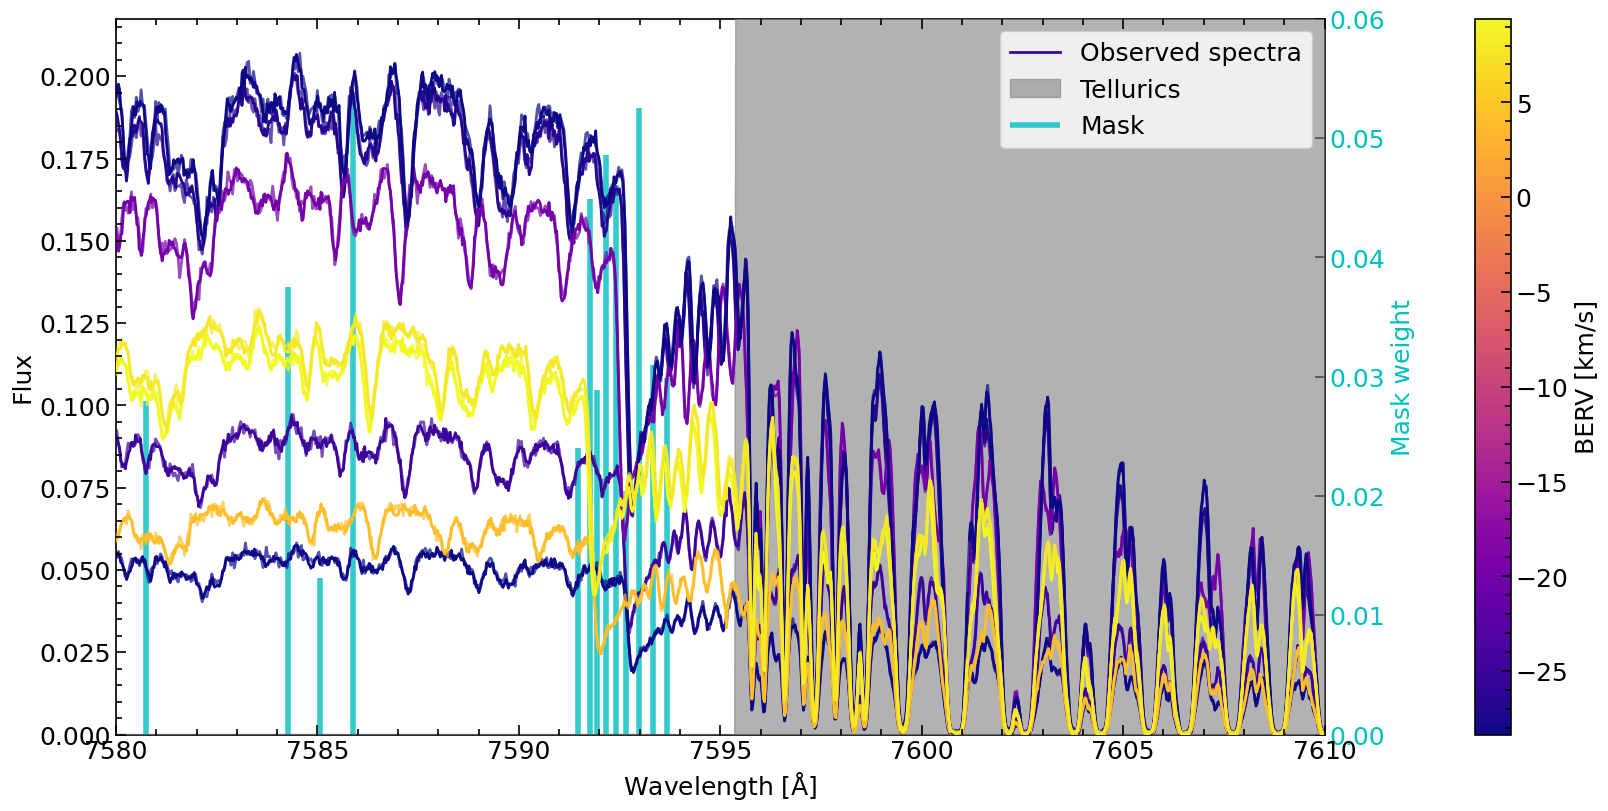

(None, None)

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(16, 8), constrained_layout=True)
# Spectrum
ax = lisspec.plot_spectra(ax=ax, wmin=7580, wmax=7610, lw=2, legendwhich='first', legendlabel='Observed spectra', cprop=lisspec.dataheader['berv'], cbarlabel='BERV [km/s]', cmap='plasma')
ylim = ax.get_ylim()

# # Binary mask
# ax = mask.plot_mask(ax=ax, ymin=ylim[0], yscale=2, linewidths=4, color='c')
# Binary mask in new axis
ax2 = ax.twinx()  # instantiate a second Axes that shares the same x-axis
ax2 = mask.plot_mask(ax=ax2, ymin=0, linewidths=4, color='c', keeplims=False, zorder=-2, leglabel='Mask')
ax2.tick_params(axis='y', labelcolor='c')
ax2.set_ylabel('Mask weight', color='c')
ax2.set_ylim(0, 0.06)

# Telluric mask
ax = tellmask.plot_mask(ax=ax, fscale=ylim[1], zorder=-3, leglabel='Tellurics')

# Format
ax.set_zorder(ax2.get_zorder()+1)
ax.set_frame_on(False)
ax.set_ylim(0, ylim[1])
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2)
plt.show(), plt.close()

## Apply BERV correction

## Compute CCF

In [11]:
# Prepare CCF inputs

In [12]:
# Compute CCF

In [13]:
# Plot CCF